In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator, griddata, interp1d
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm
import matplotlib.gridspec as gridspec
import gc

import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import xarray as xr
## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import pandas as pd
from pyproj import Transformer
import time
from scipy.interpolate import interp1d
from scipy import special

In [3]:
def compute_k_eff(d_total, d_i, k_i):
    return d_total/np.sum(d_i/k_i)

def build_layers(d_total, scenario, n_layers, k_high, k_low, k0, A):
    dz = d_total/n_layers
    z_mid = np.linspace(dz/2, d_total - dz/2, n_layers)
    d_i = np.full(n_layers,dz)
 
    if scenario == 1:
        k_i = np.full(n_layers, k_high)
    elif scenario == 2:
        k_i = np.where(z_mid <= 0.75 * d_total, k_high, k_low)
    elif scenario == 3:
        k_i = np.where(z_mid <= 0.25 * d_total, k_high, k_low)
    elif scenario == 4:
        k_i = k0 * np.exp(-A * z_mid)
    return z_mid, d_i, k_i

In [4]:
thicknesses = [500, 1000, 3000, 4000]
thickness_labels = ["500 m", "1 km", "3 km", "4 km"]
 
k_high = 1e-13
k_low = 1e-17
k0 = 1e-13
A = 5e-3

n_layers = 200

cmap = cmocean.cm.haline
norm = LogNorm(vmin=1e-21, vmax=1e-13)

scenario_titles = [
    r"(1) Uniform $k = 10^{-13}$",
    r"(2) 75% high-$k$ / 25% low-$k$",
    r"(3) 25% high-$k$ / 75% low-$k$",
    r"(4) Exponential decay",
]

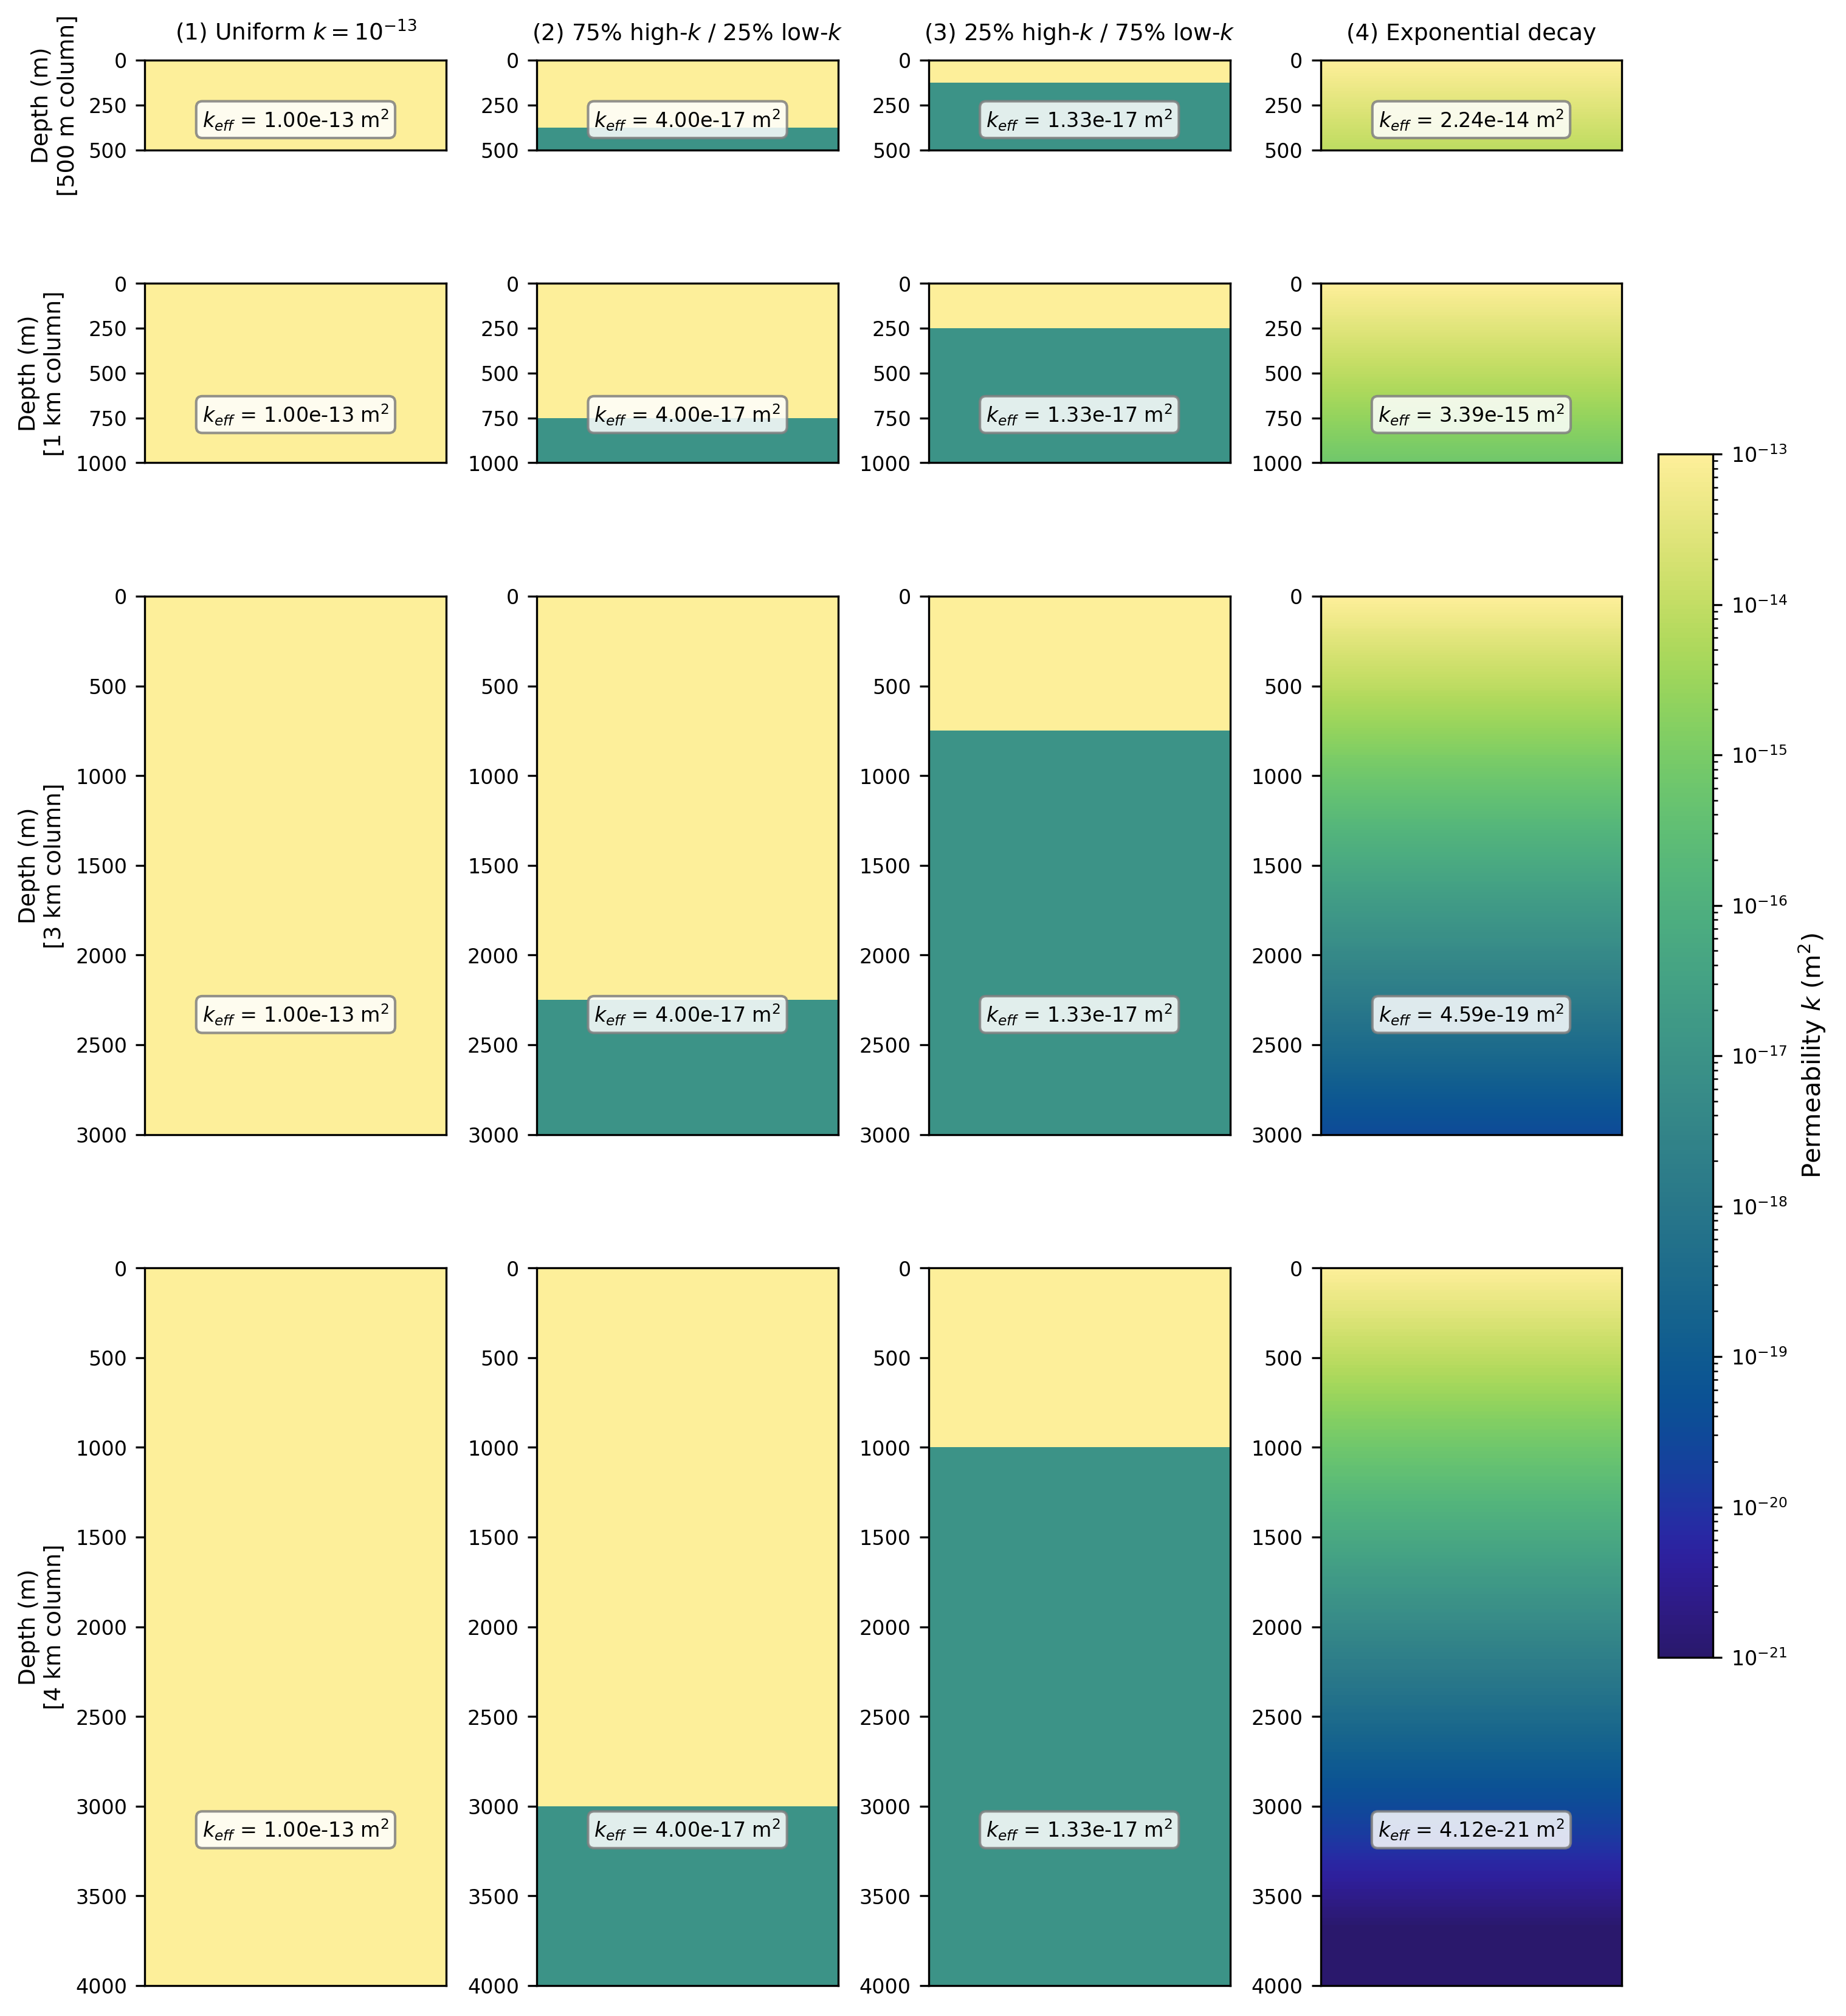

In [5]:
fig = plt.figure(figsize=(10,12),dpi=300)
 
gs = gridspec.GridSpec(
    nrows=4, ncols=4,
    height_ratios=thicknesses,
    hspace=0.35, wspace=0.30,
    left=0.07, right=0.88, top=0.93, bottom=0.05,
)
 
axes = np.empty((4, 4), dtype=object)
for row in range(4):
    for col in range(4):
        axes[row, col] = fig.add_subplot(gs[row, col])
 
for row, (d_total, d_label) in enumerate(zip(thicknesses, thickness_labels)):
    for col, (sc_num, sc_title) in enumerate(zip([1, 2, 3, 4], scenario_titles)):
        ax = axes[row, col]
 
        z_mid, d_i, k_i = build_layers(d_total, sc_num, n_layers, k_high, k_low, k0, A)
        keff = compute_k_eff(d_total, d_i, k_i)
 
        colors = cmap(norm(k_i))
        bar_height = d_i[0]
        ax.barh(
            z_mid, 1, height=bar_height,
            color=colors, edgecolor="none",
        )
 
        ax.set_xlim(0,1)
        ax.set_ylim(d_total, 0)
        ax.set_xticks([])
        ax.tick_params(axis="y", labelsize=8)
 
        ax.text(
            0.50, 0.2,
            r"$k_{{eff}}$ = {:.2e} m$^2$".format(keff),
            transform=ax.transAxes, fontsize=8,
            ha="center", va="bottom",
            bbox=dict(boxstyle="round,pad=0.3", fc="white",
                      ec="gray", alpha=0.85),
        )
 
        if row == 0:
            ax.set_title(sc_title, fontsize=9, pad=8)
 
        if col == 0:
            ax.set_ylabel(f"Depth (m)\n[{d_label} column]", fontsize=9)
 
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar_ax = fig.add_axes([0.90, 0.20, 0.03, 0.55])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label(r"Permeability $k$ (m$^2$)", fontsize=10)
cbar.ax.tick_params(labelsize=8)